# Дополнительное задание. Пайплайн обучения нейронной сети

Цель — собрать на TensorFlow полный цикл классификации: подготовка данных, baseline, 5-кратная стратифицированная кросс-валидация, полный перебор гиперпараметров и мониторинг обучения в TensorBoard.

Датасет тот же, что в лабораторной работе 2: Pima Indians Diabetes. Объект — пациентка, целевая переменная `Outcome` (0 — диабета нет, 1 — диабет есть). Она зависит от восьми числовых признаков.

Сетка гиперпараметров, которую требует задание:

- скорость обучения — 3 значения: 0.01, 0.001 и 0.0001;
- архитектура — 3 варианта: один скрытый слой, два слоя с dropout и три слоя с более сильным dropout.

Отложенная тестовая выборка не участвует в выборе конфигурации. По ней один раз считается baseline и один раз — уже выбранная сеть.

In [1]:
%matplotlib inline

import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "diabetes.csv"
OUTPUT_DIR = ROOT / "output" / "extra"
TB_DIR = ROOT / "output" / "tensorboard_extra"
if not DATA_PATH.exists():
    raise FileNotFoundError("Запустите ноутбук из папки MO_2lab, рядом с data/diabetes.csv")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TB_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
EPOCHS = 40
BATCH_SIZE = 32

FEATURES = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]
TARGET = "Outcome"
MISSING_AS_ZERO = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
LABELS = {
    "Pregnancies": "Беременности",
    "Glucose": "Глюкоза",
    "BloodPressure": "Давление",
    "SkinThickness": "Толщина кожи",
    "Insulin": "Инсулин",
    "BMI": "Индекс массы тела",
    "DiabetesPedigreeFunction": "Родословная",
    "Age": "Возраст",
    "Outcome": "Диабет",
}

ARCHITECTURES = [
    {"name": "8 нейронов", "hidden": (8,), "dropout": 0.0},
    {"name": "32-16, dropout 0.2", "hidden": (32, 16), "dropout": 0.2},
    {"name": "64-32-16, dropout 0.3", "hidden": (64, 32, 16), "dropout": 0.3},
]
LEARNING_RATES = [1e-2, 1e-3, 1e-4]


def lr_label(value):
    return f"{float(value):.4f}".rstrip("0").rstrip(".")

np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


### 1. Загрузка и первичный анализ

Файл `data/diabetes.csv` — таблица из лабораторной работы 2. Смотрим размер, типы, явные пропуски, нули в физиологических измерениях и баланс классов.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Размер: (768, 9)


,тип,роль
столбец,,
Pregnancies,int64,признак
Glucose,int64,признак
BloodPressure,int64,признак
SkinThickness,int64,признак
Insulin,int64,признак
BMI,float64,признак
DiabetesPedigreeFunction,float64,признак
Age,int64,признак
Outcome,int64,целевая переменная


,явные пропуски
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


,нули
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


,число,доля
Outcome,,
нет диабета,500,0.651
диабет,268,0.349


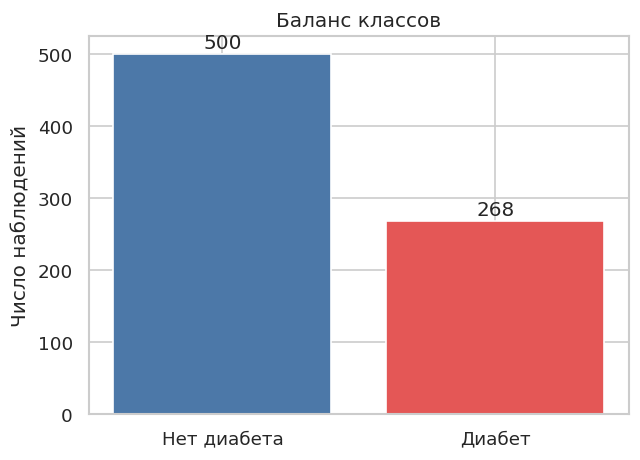

In [2]:
raw = pd.read_csv(DATA_PATH)
display(raw.head())
print("Размер:", raw.shape)

dtypes = raw.dtypes.rename("тип").rename_axis("столбец").to_frame()
dtypes["роль"] = ["признак"] * len(FEATURES) + ["целевая переменная"]
display(dtypes)

isna_count = raw.isna().sum().rename("явные пропуски")
zero_count = pd.Series(
    {column: int((raw[column] == 0).sum()) for column in MISSING_AS_ZERO},
    name="нули",
)
display(isna_count.to_frame())
display(zero_count.to_frame())

class_counts = raw[TARGET].value_counts().sort_index().rename({0: "нет диабета", 1: "диабет"})
class_share = (class_counts / len(raw)).rename("доля")
display(pd.concat([class_counts.rename("число"), class_share], axis=1).round(3))

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(["Нет диабета", "Диабет"], class_counts.values, color=["#4C78A8", "#E45756"])
ax.set_ylabel("Число наблюдений")
ax.set_title("Баланс классов")
for bar, value in zip(ax.patches, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 8, str(value), ha="center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_class_balance.png", bbox_inches="tight")
plt.show()

### Вывод о данных и предобработке

В таблице 768 наблюдений и 9 столбцов. Все признаки и метка уже числовые: `int64` или `float64`. Категориальных столбцов нет, поэтому кодировщик вроде one-hot не нужен.

Явных пропусков `NaN` в файле нет. Ноль в глюкозе, давлении, толщине кожи, инсулине и индексе массы тела физиологически невозможен: таких нулей 5, 35, 227, 374 и 11. Дальше они считаются пропусками и заменяются медианой. Ноль в числе беременностей — настоящее значение, его не трогаем.

Классы несбалансированы умеренно: 500 пациенток без диабета и 268 с диабетом, доля положительного класса около 0,349. Константный ответ «диабета нет» дал бы accuracy около 0,65, поэтому высокую accuracy нельзя читать в отрыве от этого пола. Дополнительный ресемплинг не делаю: большинства не настолько много, чтобы класс исчез, а переписывание выборки смешало бы сравнение baseline и сетки. Вместо этого разбиение на тест и на фолды стратифицируется, и медиана с масштабом считаются только по обучающей части соответствующего разбиения.

### Разделение на признаки, цель, обучение и тест

Нули из пяти измерений заменяются на пропуск до разбиения: это правило, а не статистика, оцененная по данным. Медиана оценивается уже после разбиения и только по обучающей части. Те же 20% с `random_state=42` и `stratify=y`, что и в основной лабораторной, остаются отложенным тестом.

In [3]:
clean = raw.copy()
for column in MISSING_AS_ZERO:
    clean.loc[clean[column] == 0, column] = np.nan

x = clean[FEATURES]
y = clean[TARGET].astype(int)
x_train_raw, x_test_raw, y_train, y_test = train_test_split(
    x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

train_median = x_train_raw.median()
x_train = x_train_raw.fillna(train_median)
x_test = x_test_raw.fillna(train_median)

print(f"Обучающая выборка: {len(x_train)}")
print(f"Тестовая выборка: {len(x_test)}")
print("Классы в обучении:", y_train.value_counts().sort_index().to_dict())
print("Классы в тесте:", y_test.value_counts().sort_index().to_dict())
display(train_median.rename(LABELS).round(3).to_frame("медиана обучающей выборки"))

Обучающая выборка: 614
Тестовая выборка: 154
Классы в обучении: {0: 400, 1: 214}
Классы в тесте: {0: 100, 1: 54}


,медиана обучающей выборки
Беременности,3.000
Глюкоза,117.000
Давление,72.000
Толщина кожи,29.000
Инсулин,125.000
Индекс массы тела,32.400
Родословная,0.382
Возраст,29.000


### 2. Baseline-модель

Точка отсчёта — логистическая регрессия. Это линейный классификатор с сигмоидой на выходе: как раз простая модель, с которой дальше сравнивается настроенная сеть. Перед ней стоит `StandardScaler`, обученный только на обучающей выборке. Порог решения стандартный, 0,5. Рядом печатается accuracy константы «всегда нет диабета»: это пол, ниже которого модель неинформативна.

In [4]:
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
baseline.fit(x_train, y_train)
baseline_probability = baseline.predict_proba(x_test)[:, 1]
baseline_prediction = baseline.predict(x_test)
baseline_accuracy = accuracy_score(y_test, baseline_prediction)
baseline_loss = log_loss(y_test, baseline_probability)
majority_accuracy = float((y_test == y_train.mode().iloc[0]).mean())

print(f"Baseline, логистическая регрессия: accuracy = {baseline_accuracy:.3f}, log loss = {baseline_loss:.3f}")
print(f"Accuracy класса большинства на тесте: {majority_accuracy:.3f}")

Baseline, логистическая регрессия: accuracy = 0.708, log loss = 0.514
Accuracy класса большинства на тесте: 0.649


### 3. Сетка гиперпараметров и 5-кратная кросс-валидация

Перебор полный: `ParameterGrid` даёт 3 скорости × 3 архитектуры = 9 конфигураций. Каждая оценивается на `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. Фолды нарезаются только из обучающих 614 объектов. В каждом фолде около 491 объекта идёт в обучение сети и около 123 — в проверку, доля диабета сохраняется.

`GridSearchCV` здесь не используется как чёрный ящик. На каждом фолде нужно заново оценить медиану и `StandardScaler` только по обучающей части фолда и записать отдельный каталог TensorBoard с кривыми обучения и проверки. Это тот же полный grid search, но шаг фолда виден явно.

Сеть — `Sequential`. Скрытые слои с ReLU, после них dropout, если он задан архитектурой. Выход — один нейрон с сигмоидой, потому что класс один и метка равна 0 или 1. Функция потерь — бинарная кросс-энтропия, оптимизатор — Adam, метрика для мониторинга — accuracy. Число эпох 40 и размер батча 32 зафиксированы: в сетке меняются только скорость и архитектура.

Лучшая конфигурация выбирается по средней validation accuracy на последней эпохе. Тест в этом выборе не участвует.

In [5]:
def set_seeds(seed):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.keras.utils.set_random_seed(seed)


def make_network(n_features, hidden, dropout, learning_rate):
    tf.keras.backend.clear_session()
    layers = [tf.keras.layers.Input(shape=(n_features,))]
    for units in hidden:
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


def prepare_fold(frame, train_index, valid_index):
    fold_train = frame.iloc[train_index]
    fold_valid = frame.iloc[valid_index]
    medians = fold_train.median()
    scaler = StandardScaler()
    x_tr = scaler.fit_transform(fold_train.fillna(medians).to_numpy(dtype=float))
    x_va = scaler.transform(fold_valid.fillna(medians).to_numpy(dtype=float))
    return x_tr, x_va


for architecture in ARCHITECTURES:
    print(architecture["name"])
    preview = make_network(len(FEATURES), architecture["hidden"], architecture["dropout"], 1e-3)
    preview.summary()

search_space = list(ParameterGrid({
    "learning_rate": LEARNING_RATES,
    "architecture_index": [0, 1, 2],
}))
print(f"Размер сетки: {len(search_space)} конфигураций, фолдов: {N_SPLITS}")

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
fold_rows = []
histories = {}

for params in search_space:
    architecture = ARCHITECTURES[params["architecture_index"]]
    learning_rate = float(params["learning_rate"])
    for fold, (train_index, valid_index) in enumerate(cv.split(x_train_raw, y_train)):
        x_tr, x_va = prepare_fold(x_train_raw, train_index, valid_index)
        y_tr = y_train.iloc[train_index].to_numpy()
        y_va = y_train.iloc[valid_index].to_numpy()
        set_seeds(RANDOM_STATE + fold)
        model = make_network(x_tr.shape[1], architecture["hidden"], architecture["dropout"], learning_rate)
        log_dir = TB_DIR / f"arch{params['architecture_index']}_lr{lr_label(learning_rate)}" / f"fold_{fold}"
        callback = tf.keras.callbacks.TensorBoard(
            log_dir=str(log_dir),
            histogram_freq=0,
            write_graph=False,
            update_freq="epoch",
        )
        started = time.perf_counter()
        history = model.fit(
            x_tr,
            y_tr,
            validation_data=(x_va, y_va),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[callback],
            verbose=0,
        )
        seconds = time.perf_counter() - started
        record = history.history
        fold_rows.append({
            "architecture": architecture["name"],
            "learning_rate": learning_rate,
            "lr_label": lr_label(learning_rate),
            "fold": fold,
            "val_accuracy": float(record["val_accuracy"][-1]),
            "val_loss": float(record["val_loss"][-1]),
            "train_accuracy": float(record["accuracy"][-1]),
            "train_loss": float(record["loss"][-1]),
            "seconds": seconds,
        })
        histories[(architecture["name"], lr_label(learning_rate), fold)] = record
        print(
            f"{architecture['name']} | lr={lr_label(learning_rate)} | fold={fold} | "
            f"val_acc={record['val_accuracy'][-1]:.3f} | {seconds:.1f} c",
            flush=True,
        )
        del model

fold_df = pd.DataFrame(fold_rows)
fold_df.to_csv(OUTPUT_DIR / "cv_folds.csv", index=False, encoding="utf-8-sig")
summary = (
    fold_df.groupby(["architecture", "learning_rate", "lr_label"], as_index=False)
    .agg(
        mean_val_accuracy=("val_accuracy", "mean"),
        std_val_accuracy=("val_accuracy", "std"),
        min_val_accuracy=("val_accuracy", "min"),
        max_val_accuracy=("val_accuracy", "max"),
        mean_val_loss=("val_loss", "mean"),
        mean_train_accuracy=("train_accuracy", "mean"),
        mean_train_loss=("train_loss", "mean"),
        mean_seconds=("seconds", "mean"),
    )
    .sort_values(
        ["mean_val_accuracy", "std_val_accuracy", "mean_val_loss"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)
summary.to_csv(OUTPUT_DIR / "cv_summary.csv", index=False, encoding="utf-8-sig")
display(
    summary.drop(columns=["learning_rate"])
    .rename(columns={
        "architecture": "архитектура",
        "lr_label": "learning rate",
        "mean_val_accuracy": "CV accuracy",
        "std_val_accuracy": "std accuracy",
        "min_val_accuracy": "min accuracy",
        "max_val_accuracy": "max accuracy",
        "mean_val_loss": "CV loss",
        "mean_train_accuracy": "train accuracy",
        "mean_train_loss": "train loss",
        "mean_seconds": "секунды на фолд",
    })
    .round(3)
)

8 нейронов


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81 (324.00 B)

 Trainable params: 81 (324.00 B)

 Non-trainable params: 0 (0.00 B)

... (55 outputs left out)

64-32-16, dropout 0.3 | lr=0.0001 | fold=2 | val_acc=0.805 | 4.5 c


64-32-16, dropout 0.3 | lr=0.0001 | fold=3 | val_acc=0.715 | 4.5 c


64-32-16, dropout 0.3 | lr=0.0001 | fold=4 | val_acc=0.730 | 4.5 c


,архитектура,learning rate,CV accuracy,std accuracy,min accuracy,max accuracy,CV loss,train accuracy,train loss,секунды на фолд
0,"64-32-16, dropout 0.3",0.001,0.790,0.018,0.770,0.813,0.455,0.792,0.440,4.511
1,"32-16, dropout 0.2",0.001,0.783,0.014,0.770,0.805,0.459,0.803,0.427,4.267
2,8 нейронов,0.01,0.775,0.021,0.764,0.813,0.479,0.820,0.390,4.051
3,"64-32-16, dropout 0.3",0.01,0.775,0.022,0.756,0.813,0.542,0.835,0.369,4.488
4,"32-16, dropout 0.2",0.01,0.762,0.010,0.748,0.772,0.544,0.842,0.347,4.282
5,8 нейронов,0.001,0.759,0.032,0.715,0.805,0.470,0.771,0.458,4.012
6,"64-32-16, dropout 0.3",0.0001,0.756,0.037,0.715,0.805,0.524,0.712,0.555,4.507
7,"32-16, dropout 0.2",0.0001,0.710,0.046,0.659,0.780,0.528,0.701,0.548,4.290
8,8 нейронов,0.0001,0.489,0.109,0.374,0.664,0.782,0.495,0.762,4.019


### 4. Сравнение конфигураций

В таблице выше каждая строка — одна ячейка сетки. `mean_val_accuracy` и `mean_val_loss` — средние по пяти фолдам на последней эпохе. `std_val_accuracy` показывает, насколько фолды расходятся: чем она меньше, тем устойчивее конфигурация. `mean_seconds` — среднее время одного `fit`.

Лучшая строка стоит первой: максимальная средняя accuracy, при равенстве — меньший разброс по фолдам, затем меньшая validation loss.

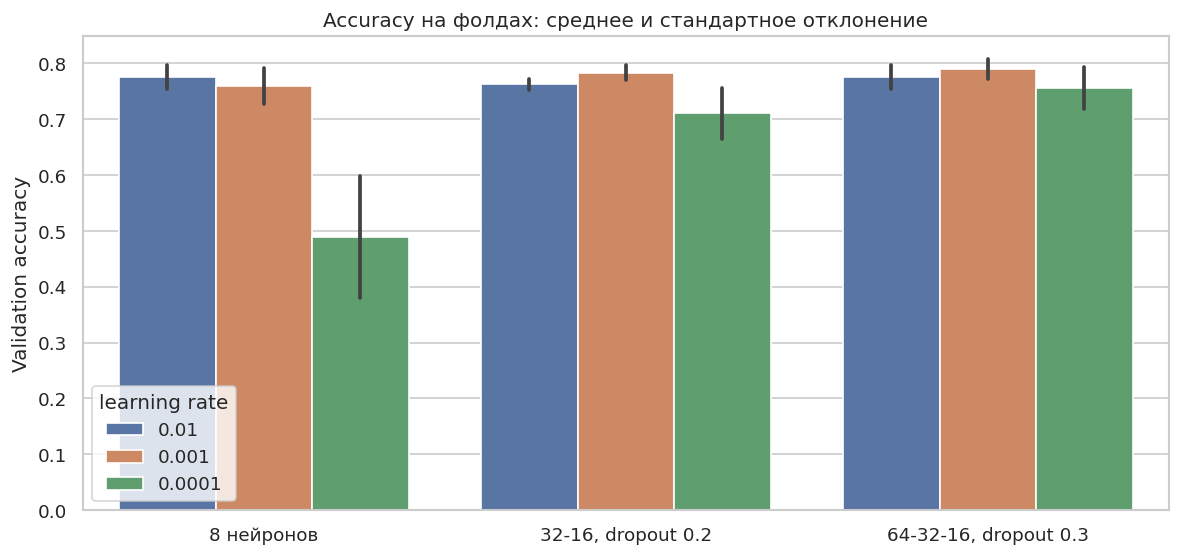

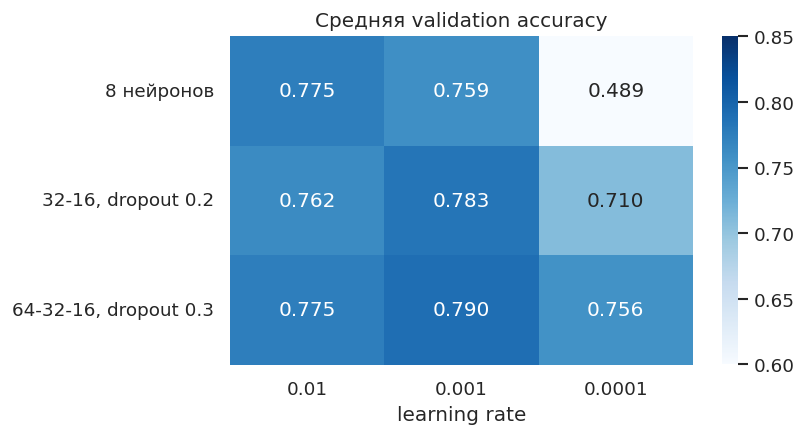

Лучшая конфигурация: 64-32-16, dropout 0.3, learning rate = 0.001, CV accuracy = 0.790 ± 0.018, CV loss = 0.455, время фолда = 4.5 c


In [6]:
best = summary.iloc[0]
arch_order = [item["name"] for item in ARCHITECTURES]
lr_order = [lr_label(value) for value in LEARNING_RATES]

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(
    data=fold_df,
    x="architecture",
    y="val_accuracy",
    hue="lr_label",
    order=arch_order,
    hue_order=lr_order,
    errorbar="sd",
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Validation accuracy")
ax.set_title("Accuracy на фолдах: среднее и стандартное отклонение")
ax.legend(title="learning rate")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_cv_accuracy.png", bbox_inches="tight")
plt.show()

heat = summary.pivot(index="architecture", columns="lr_label", values="mean_val_accuracy")
heat = heat.reindex(index=arch_order, columns=lr_order)
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", vmin=0.6, vmax=0.85, ax=ax)
ax.set_xlabel("learning rate")
ax.set_ylabel("")
ax.set_title("Средняя validation accuracy")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_accuracy_heatmap.png", bbox_inches="tight")
plt.show()

print(
    f"Лучшая конфигурация: {best['architecture']}, learning rate = {best['lr_label']}, "
    f"CV accuracy = {best['mean_val_accuracy']:.3f} ± {best['std_val_accuracy']:.3f}, "
    f"CV loss = {best['mean_val_loss']:.3f}, время фолда = {best['mean_seconds']:.1f} c"
)

### 5. Мониторинг обучения

На каждом фолде в `fit` передан callback TensorBoard. Каталог логов:

`output/tensorboard_extra/arch<номер>_lr<скорость>/fold_<номер>`

Туда пишутся accuracy и loss обучения и проверки, потому что в `fit` задан `validation_data` фолда. Запуск из папки проекта:

```
tensorboard --logdir output/tensorboard_extra
```

В интерфейсе можно включить два запуска, например `arch0_lr0.001` и `arch2_lr0.01`, и сравнить кривые. Ниже те же скаляры собраны из `history` и усреднены по фолдам, чтобы сравнение было видно прямо в ноутбуке. Отдельный рисунок для лучшей конфигурации накладывает обучение и проверку: растущий зазор и подъём validation loss — признак переобучения, а вместе растущие кривые к концу 40 эпох — признак того, что сеть ещё не доучилась.

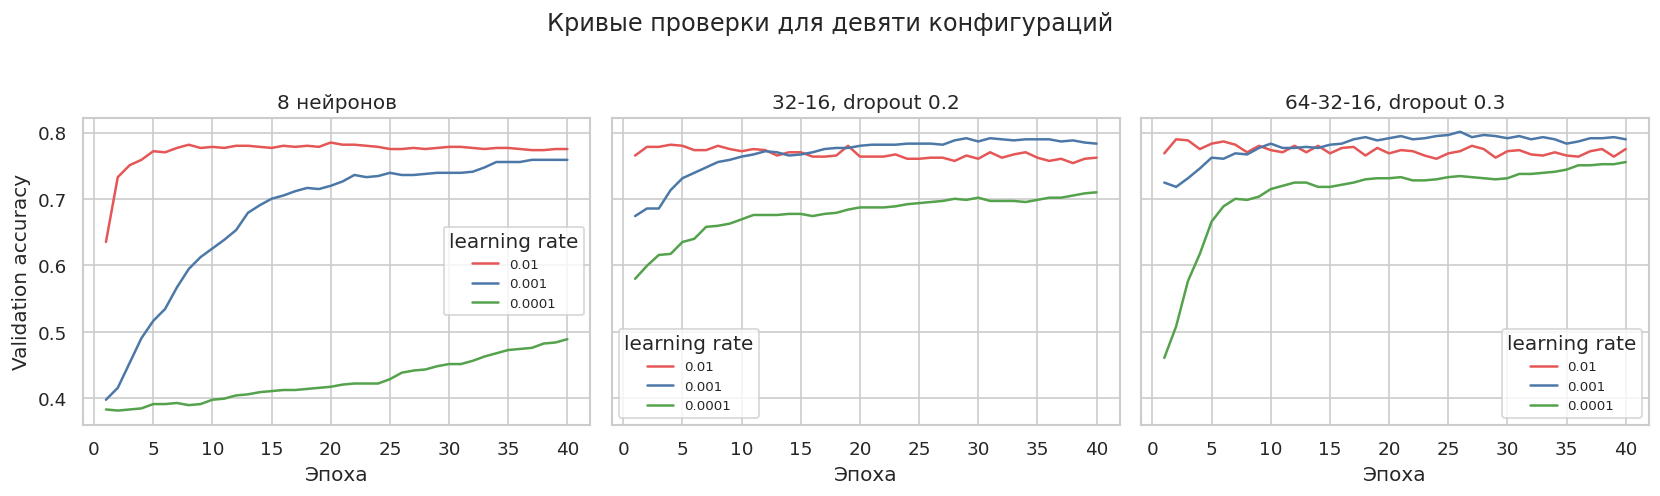

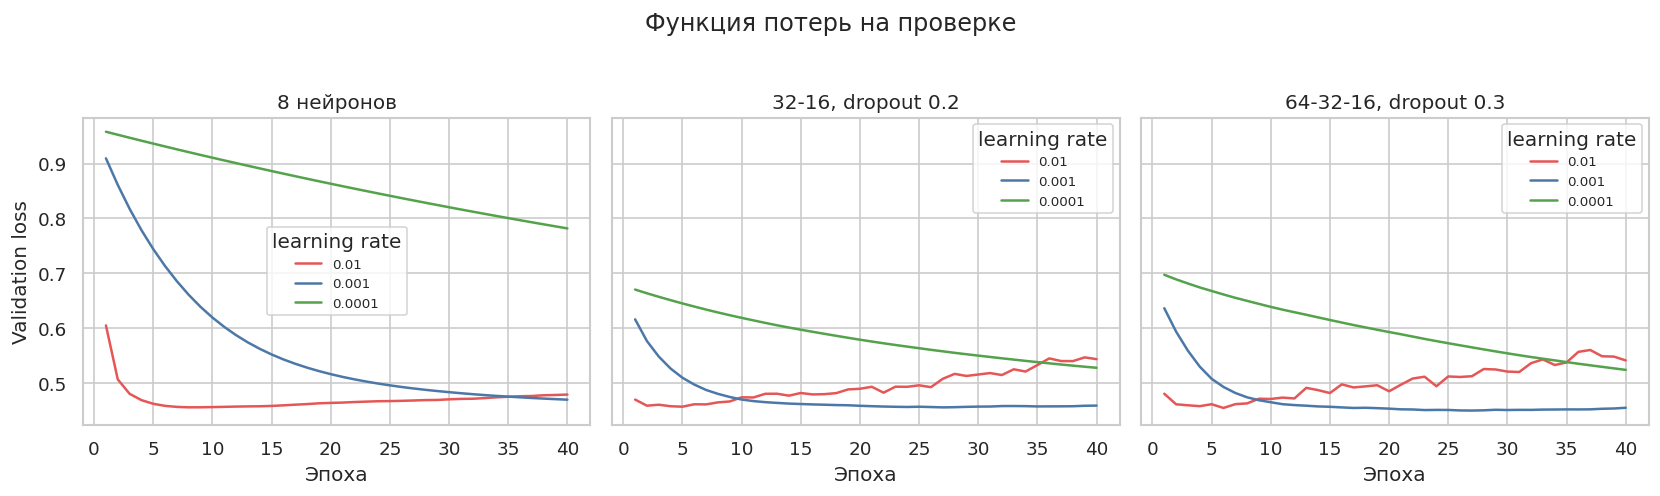

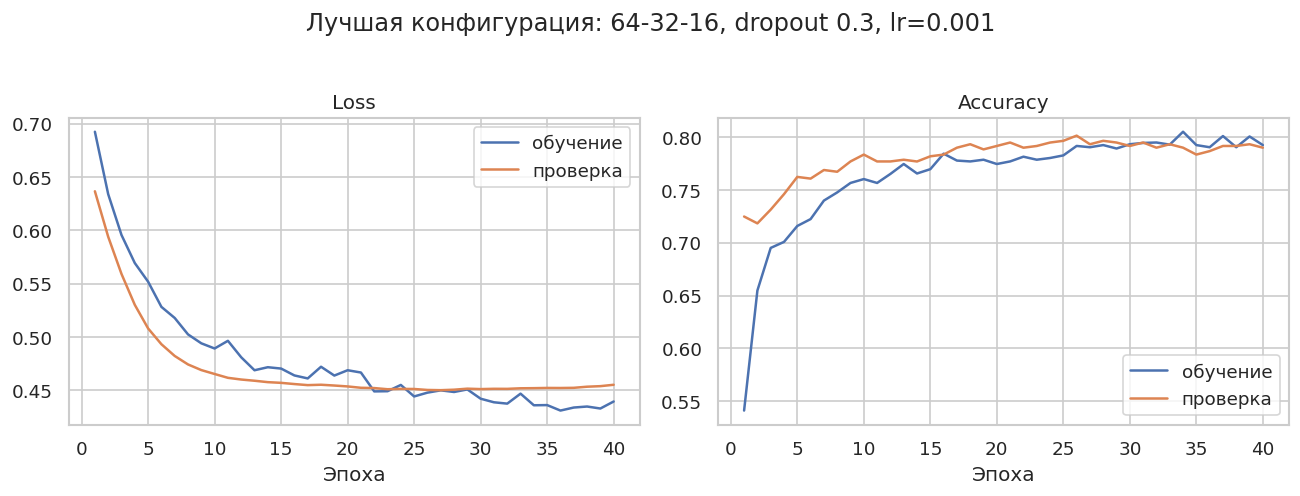

In [7]:
def mean_curve(architecture, label, key):
    architecture = str(architecture)
    label = str(label)
    curves = [histories[(architecture, label, fold)][key] for fold in range(N_SPLITS)]
    return np.vstack(curves).mean(axis=0)


epochs_axis = np.arange(1, EPOCHS + 1)
colors = {label: color for label, color in zip(lr_order, ["#E45756", "#4C78A8", "#54A24B"])}

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, architecture in zip(axes, arch_order):
    for label in lr_order:
        ax.plot(epochs_axis, mean_curve(architecture, label, "val_accuracy"), color=colors[label], label=label)
    ax.set_title(architecture)
    ax.set_xlabel("Эпоха")
    ax.legend(title="learning rate", fontsize=8)
axes[0].set_ylabel("Validation accuracy")
fig.suptitle("Кривые проверки для девяти конфигураций", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_val_accuracy_curves.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, architecture in zip(axes, arch_order):
    for label in lr_order:
        ax.plot(epochs_axis, mean_curve(architecture, label, "val_loss"), color=colors[label], label=label)
    ax.set_title(architecture)
    ax.set_xlabel("Эпоха")
    ax.legend(title="learning rate", fontsize=8)
axes[0].set_ylabel("Validation loss")
fig.suptitle("Функция потерь на проверке", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_val_loss_curves.png", bbox_inches="tight")
plt.show()

chosen_label = best["lr_label"]
chosen_name = best["architecture"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, train_key, val_key, title in (
    (axes[0], "loss", "val_loss", "Loss"),
    (axes[1], "accuracy", "val_accuracy", "Accuracy"),
):
    ax.plot(epochs_axis, mean_curve(chosen_name, chosen_label, train_key), label="обучение")
    ax.plot(epochs_axis, mean_curve(chosen_name, chosen_label, val_key), label="проверка")
    ax.set_xlabel("Эпоха")
    ax.set_title(title)
    ax.legend()
fig.suptitle(f"Лучшая конфигурация: {chosen_name}, lr={best['lr_label']}", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_best_train_val.png", bbox_inches="tight")
plt.show()

### 6. Финальная оценка

Выбранная архитектура и скорость заново обучаются на всей обучающей выборке. Медиана и `StandardScaler` считаются по всем 614 объектам и применяются к тесту. Тест не передаётся в `fit` как validation и не используется для ранней остановки. После 40 эпох один раз считаются accuracy и log loss. Их сравниваем с логистической регрессией.

Эффект настройки считается внутри сетки: насколько средняя accuracy меняется при смене скорости, если усреднить архитектуры, и наоборот. Больший разброс — более влиятельный гиперпараметр. Разрыв train/val у лучшей конфигурации и форма validation loss показывают переобучение или недообучение.

In [8]:
chosen = next(item for item in ARCHITECTURES if item["name"] == best["architecture"])
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train.to_numpy(dtype=float))
x_test_scaled = scaler.transform(x_test.to_numpy(dtype=float))
set_seeds(RANDOM_STATE)
final_model = make_network(
    x_train_scaled.shape[1], chosen["hidden"], chosen["dropout"], float(best["learning_rate"])
)
final_model.fit(
    x_train_scaled,
    y_train.to_numpy(),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[tf.keras.callbacks.TensorBoard(
        log_dir=str(TB_DIR / "final"),
        histogram_freq=0,
        write_graph=False,
        update_freq="epoch",
    )],
    verbose=0,
)
final_probability = final_model.predict(x_test_scaled, verbose=0).ravel()
final_prediction = (final_probability >= 0.5).astype(int)
final_accuracy = accuracy_score(y_test, final_prediction)
final_loss = log_loss(y_test, np.clip(final_probability, 1e-7, 1 - 1e-7))
final_model.summary()

by_lr = summary.groupby("lr_label")["mean_val_accuracy"].mean().reindex(lr_order)
by_arch = summary.groupby("architecture")["mean_val_accuracy"].mean().reindex(arch_order)
lr_span = float(by_lr.max() - by_lr.min())
arch_span = float(by_arch.max() - by_arch.min())
fixed = summary[(summary["architecture"] == "8 нейронов") & (summary["lr_label"] == "0.001")].iloc[0]
gap = float(best["mean_train_accuracy"] - best["mean_val_accuracy"])
val_loss_curve = mean_curve(chosen["name"], best["lr_label"], "val_loss")
val_acc_curve = mean_curve(chosen["name"], best["lr_label"], "val_accuracy")
loss_rose = float(val_loss_curve[-1] - val_loss_curve[EPOCHS // 2])
acc_still_grows = float(val_acc_curve[-5:].mean() - val_acc_curve[10:15].mean())

if gap > 0.05 and loss_rose > 0.01:
    fit_text = (
        f"Есть признак переобучения: accuracy обучения выше проверки на {gap:.3f}, "
        f"а validation loss к концу выше, чем в середине, на {loss_rose:.3f}."
    )
elif acc_still_grows > 0.01 and gap < 0.05:
    fit_text = (
        f"Сильного переобучения нет, разрыв train/val равен {gap:.3f}. "
        f"Validation accuracy всё ещё подрастает к 40-й эпохе (примерно на {acc_still_grows:.3f} "
        "относительно эпох 11–15), так что по числу эпох сеть скорее немного недообучена."
    )
else:
    fit_text = (
        f"Кривые обучения и проверки расходятся слабо: разрыв accuracy равен {gap:.3f}. "
        "Явного переобучения по validation loss не видно, и к 40-й эпохе рост проверки уже невелик."
    )

if lr_span > arch_span:
    influence = (
        f"Сильнее повлияла скорость обучения. Средняя accuracy по архитектурам "
        f"меняется на {lr_span:.3f} при смене learning rate и на {arch_span:.3f} при смене архитектуры."
    )
elif arch_span > lr_span:
    influence = (
        f"Сильнее повлияла архитектура. Средняя accuracy по скоростям обучения "
        f"меняется на {arch_span:.3f} при смене архитектуры и на {lr_span:.3f} при смене learning rate."
    )
else:
    influence = (
        f"Скорость обучения и архитектура сдвинули среднюю accuracy примерно одинаково: на {lr_span:.3f}."
    )

time_min = float(summary["mean_seconds"].min())
time_max = float(summary["mean_seconds"].max())
time_text = (
    f"Время одного фолда почти не различается: от {time_min:.1f} до {time_max:.1f} с. "
    f"У выбранной сети это {float(best['mean_seconds']):.1f} с. Конфигурации разделяет качество, а не длительность обучения."
)

comparison = pd.DataFrame([
    {"Модель": "Класс большинства", "Accuracy": majority_accuracy, "Log loss": np.nan},
    {"Модель": "Логистическая регрессия", "Accuracy": baseline_accuracy, "Log loss": baseline_loss},
    {
        "Модель": f"Сеть: {best['architecture']}, lr={best['lr_label']}",
        "Accuracy": final_accuracy,
        "Log loss": final_loss,
    },
])
display(comparison.round(3))

text = f'''
### Итог

Лучшая конфигурация по средней validation accuracy — **{best['architecture']}**, learning rate **{best['lr_label']}**. На пяти фолдах accuracy = **{best['mean_val_accuracy']:.3f} ± {best['std_val_accuracy']:.3f}** (от {best['min_val_accuracy']:.3f} до {best['max_val_accuracy']:.3f}), validation loss = **{best['mean_val_loss']:.3f}**.

На отложенном тесте эта сеть получает accuracy **{final_accuracy:.3f}** и log loss **{final_loss:.3f}**. Логистическая регрессия на том же тесте: accuracy **{baseline_accuracy:.3f}**, log loss **{baseline_loss:.3f}**. Разница accuracy (сеть минус baseline) равна **{final_accuracy - baseline_accuracy:+.3f}**. Пол «всегда нет диабета» равен {majority_accuracy:.3f}, обе модели его превосходят.

Фиксированная сеть из одного слоя на 8 нейронов при learning rate 0.001, то есть точка сетки без подбора, имеет среднюю CV accuracy **{fixed['mean_val_accuracy']:.3f}**. Подбор меняет её на **{best['mean_val_accuracy'] - fixed['mean_val_accuracy']:+.3f}**.

{influence} По скоростям средние такие: {', '.join(f'{idx} → {value:.3f}' for idx, value in by_lr.items())}. По архитектурам: {', '.join(f'{idx} → {value:.3f}' for idx, value in by_arch.items())}.

{fit_text} {time_text}
'''
display(Markdown(text))
final_model.save(OUTPUT_DIR / "final_model.keras")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,605 (37.52 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,404 (25.02 KB)

,Модель,Accuracy,Log loss
0,Класс большинства,0.649,NaN
1,Логистическая регрессия,0.708,0.514
2,"Сеть: 64-32-16, dropout 0.3, lr=0.001",0.708,0.526



### Итог

Лучшая конфигурация по средней validation accuracy — **64-32-16, dropout 0.3**, learning rate **0.001**. На пяти фолдах accuracy = **0.790 ± 0.018** (от 0.770 до 0.813), validation loss = **0.455**.

На отложенном тесте эта сеть получает accuracy **0.708** и log loss **0.526**. Логистическая регрессия на том же тесте: accuracy **0.708**, log loss **0.514**. Разница accuracy (сеть минус baseline) равна **+0.000**. Пол «всегда нет диабета» равен 0.649, обе модели его превосходят.

Фиксированная сеть из одного слоя на 8 нейронов при learning rate 0.001, то есть точка сетки без подбора, имеет среднюю CV accuracy **0.759**. Подбор меняет её на **+0.031**.

Сильнее повлияла скорость обучения. Средняя accuracy по архитектурам меняется на 0.126 при смене learning rate и на 0.099 при смене архитектуры. По скоростям средние такие: 0.01 → 0.771, 0.001 → 0.777, 0.0001 → 0.652. По архитектурам: 8 нейронов → 0.674, 32-16, dropout 0.2 → 0.752, 64-32-16, dropout 0.3 → 0.774.

Сильного переобучения нет, разрыв train/val равен 0.002. Validation accuracy всё ещё подрастает к 40-й эпохе (примерно на 0.012 относительно эпох 11–15), так что по числу эпох сеть скорее немного недообучена. Время одного фолда почти не различается: от 4.0 до 4.5 с. У выбранной сети это 4.5 с. Конфигурации разделяет качество, а не длительность обучения.
